In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_style("whitegrid")

In [3]:
df =pd.read_csv('../data/sample_data.csv')
df.rename(columns={'date_time':'datetime'}, inplace=True)

In [4]:
df.head()

,user_id,item_id,category_id,behavior_type,timestamp,datetime,date,hour,weekday,weekday_cn
0,1000060,2178355,4962280,pv,1511642462,2017-11-25 20:41:02,2017-11-25,20,5,周六
1,1000060,857323,1320293,pv,1511822512,2017-11-27 22:41:52,2017-11-27,22,0,周一
2,1000060,4983347,4069500,pv,1511822555,2017-11-27 22:42:35,2017-11-27,22,0,周一
3,1000060,2952829,4145813,cart,1511823929,2017-11-27 23:05:29,2017-11-27,23,0,周一
4,1000060,2290719,4756105,pv,1511823982,2017-11-27 23:06:22,2017-11-27,23,0,周一


In [5]:
df['datetime'] = pd.to_datetime(df['datetime'])
df['date'] = pd.to_datetime(df['date'])

In [6]:
total_pv = len(df[df['behavior_type'] == 'pv'])
total_uv = df['user_id'].nunique()
daily_uv = df.groupby('date')['user_id'].nunique()
pv_users = df[df['behavior_type'] == 'pv']['user_id'].nunique()
pv_per_user = total_pv/total_uv
days = df['date'].nunique()
daily_pv_avg = total_pv/days
daily_uv_avg = daily_uv.mean()
print(f'分析周期：{days}天')
print(f'总pv:{total_pv:>12,.0f}次')
print(f"总UV:  {total_uv:>12,.0f} 人")
print(f"人均PV: {pv_per_user:>10.2f} 次/人")
print(f"日均PV: {daily_pv_avg:>10,.0f} 次/天")
print(f"日均UV: {daily_uv_avg:>10,.0f} 人/天")

分析周期：9天
总pv:   4,502,223次
总UV:        50,000 人
人均PV:      90.04 次/人
日均PV:    500,247 次/天
日均UV:     38,777 人/天


In [7]:
daily_pv = df[df['behavior_type'] == 'pv'].groupby('date').size()
daily_trend = pd.DataFrame({
    'PV': daily_pv,
    'UV': daily_uv,
})
daily_trend.index = daily_trend.index.strftime('%m-%d')
print('每日PV/UV数据：')
print(daily_trend)

每日PV/UV数据：
           PV     UV
date                
11-25  478317  35664
11-26  484807  36006
11-27  457966  35971
11-28  448039  35752
11-29  473041  36406
11-30  480455  37089
12-01  508855  38131
12-02  629446  47679
12-03  541297  46291


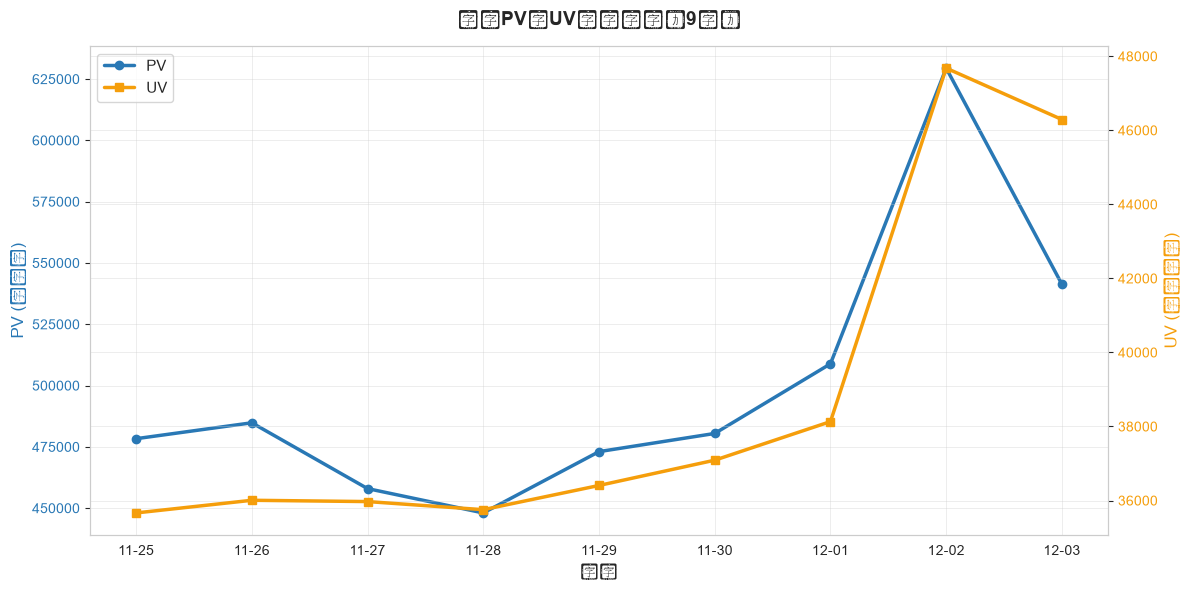

In [8]:
fig, ax1 = plt.subplots(figsize=(12, 6))
color_pv = '#2978B5'
ax1.set_xlabel('日期', fontsize=12)
ax1.set_ylabel('PV (点击量)', color=color_pv, fontsize=12)
line1 = ax1.plot(daily_trend.index, daily_trend['PV'],
                 color=color_pv, marker='o', linewidth=2.5, label='PV')
ax1.tick_params(axis='y', labelcolor=color_pv)
ax1.tick_params(axis='x', rotation=0)
ax2 = ax1.twinx()
color_uv = '#F59E0B'
ax2.set_ylabel('UV (独立用户)', color=color_uv, fontsize=12)
line2 = ax2.plot(daily_trend.index, daily_trend['UV'],
                 color=color_uv, marker='s', linewidth=2.5, label='UV')
ax2.tick_params(axis='y', labelcolor=color_uv)
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=11)
plt.title('每日PV与UV变化趋势（9天）', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../data/03_daily_pv_uv_trend.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
weekday_order = ['周一','周二','周三','周四','周五','周六','周日']
weekday_pv = df[df['behavior_type'] == 'pv'].groupby(['date','weekday_cn']).size().reset_index(name='pv')
weekday_pv_avg = weekday_pv.groupby('weekday_cn')['pv'].mean()
weekday_pv_avg = weekday_pv_avg.reindex(weekday_order)
print('各星期平均pv:')
for day,pv in weekday_pv_avg.items():
    print(f'{day}: {pv:>10,.0f}次')

各星期平均pv:
周一:    457,966次
周二:    448,039次
周三:    473,041次
周四:    480,455次
周五:    508,855次
周六:    553,882次
周日:    513,052次



工作日平均PV: 473,671
周末平均PV: 533,467
周末比工作日高: 12.6%


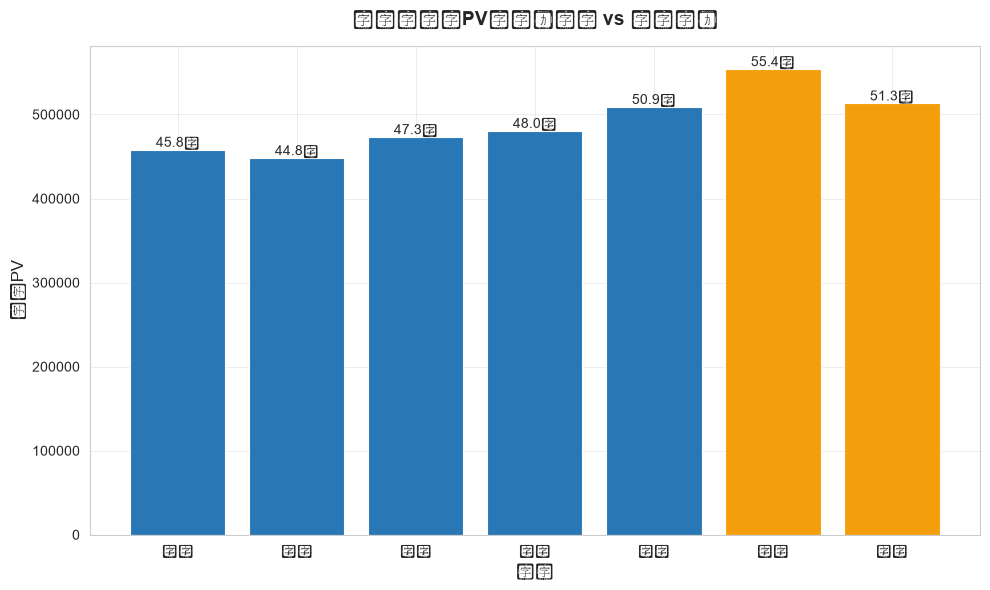

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2978B5'] * 5 + ['#F59E0B', '#F59E0B']
bars = ax.bar(weekday_pv_avg.index, weekday_pv_avg.values,color=colors,edgecolor='white', linewidth=0.8)
ax.set_xlabel('星期', fontsize=12)
ax.set_ylabel('平均PV', fontsize=12)
ax.set_title('各星期平均PV对比（周末 vs 工作日）',fontsize=14, fontweight='bold', pad=15)
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height,
            f'{height/10000:.1f}万',
            ha='center', va='bottom', fontsize=10)
    weekday_mean = weekday_pv_avg.iloc[:5].mean()
weekend_mean = weekday_pv_avg.iloc[5:].mean()
diff_pct = (weekend_mean - weekday_mean) / weekday_mean * 100

print(f"\n工作日平均PV: {weekday_mean:,.0f}")
print(f"周末平均PV: {weekend_mean:,.0f}")
print(f"周末比工作日高: {diff_pct:.1f}%")

plt.tight_layout()
plt.savefig('../data/03_weekday_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

24小时pv分布
          PV     UV  PV占比(%)
hour                        
0     153836  22409     3.42
1     187669  26240     4.17
2     219463  29200     4.87
3     214041  29727     4.75
4     217015  29917     4.82
5     236949  30312     5.26
6     236312  30022     5.25
7     242580  30431     5.39
8     237565  30210     5.28
9     215414  29737     4.78
10    220936  29422     4.91
11    276388  31722     6.14
12    334528  33612     7.43
13    381865  34560     8.48
14    375506  32667     8.34
15    286639  26099     6.37
16    139087  15248     3.09
17     64460   7954     1.43
18     35842   4612     0.80
19     23222   3299     0.52
20     20307   3100     0.45
21     26891   3944     0.60
22     54978   8346     1.22
23    100730  15688     2.24
pv最高的三个小时是[13, 14, 12]


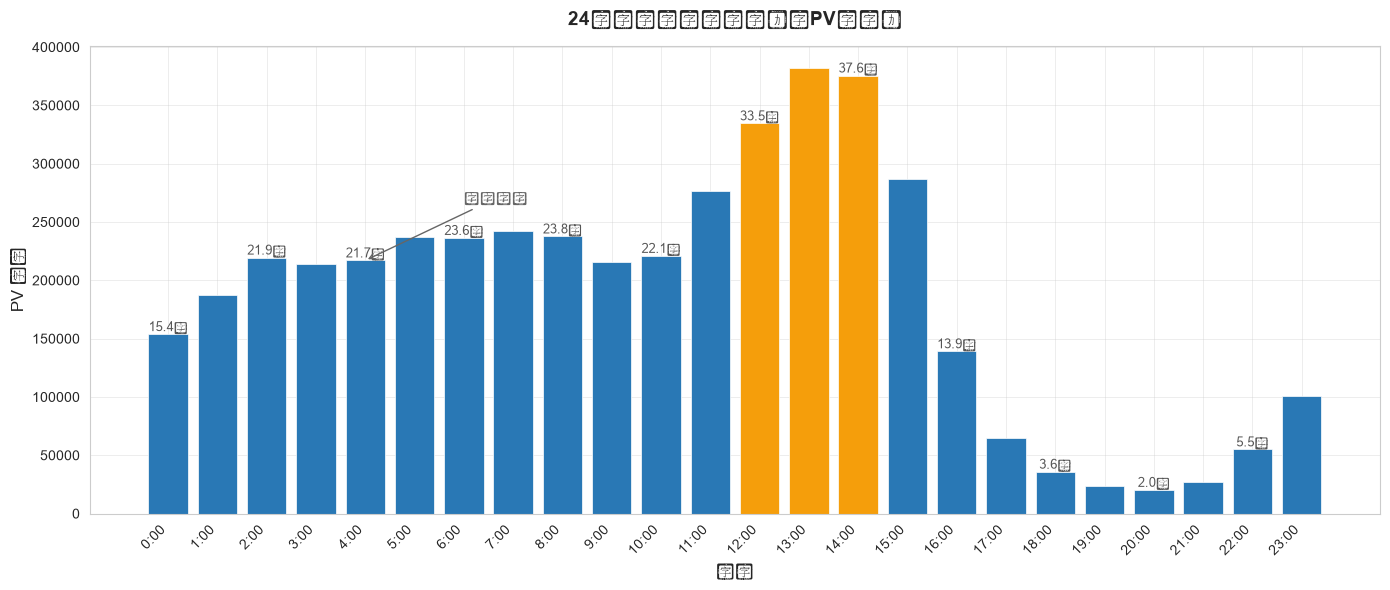

In [13]:
hourly_pv = df[df['behavior_type'] == 'pv'].groupby('hour').size()
hourly_uv = df.groupby('hour')['user_id'].nunique()
hourly_dist = pd.DataFrame({'PV': hourly_pv, 'UV': hourly_uv})
hourly_dist['PV占比(%)'] = (hourly_dist['PV'] / hourly_dist['PV'].sum() * 100).round(2)
print('24小时pv分布')
print(hourly_dist)
top_hours = hourly_dist['PV'].nlargest(3)
print(f'pv最高的三个小时是{list(top_hours.index)}')
fig, ax = plt.subplots(figsize=(14, 6))
hours = hourly_dist.index
pv_values = hourly_dist['PV']
colors = ['#2978B5' if h not in top_hours.index else '#F59E0B' for h in hours]

bars = ax.bar(hours, pv_values, color=colors, edgecolor='white', linewidth=0.5)

ax.set_xlabel('小时', fontsize=12)
ax.set_ylabel('PV 数量', fontsize=12)
ax.set_title('24小时用户活跃分布（按PV统计）', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(range(0, 24))
ax.set_xticklabels([f'{h}:00' for h in range(0, 24)], rotation=45, ha='right')
for i, bar in enumerate(bars):
    if i % 2 == 0:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height,
                f'{height/10000:.1f}万',
                ha='center', va='bottom', fontsize=9, color='#555')
ax.annotate('凌晨低谷', xy=(4, hourly_dist.loc[4, 'PV']),
            xytext=(6, hourly_dist.loc[4, 'PV'] + 50000),
            arrowprops=dict(arrowstyle='->', color='#666'),
            fontsize=10, color='#666')

plt.tight_layout()
plt.savefig('../data/03_hourly_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

四种行为统计:
             行为次数         占比
点击(pv)    4502223  89.581449
收藏(fav)    145207   2.889207
加购(cart)   277177   5.515035
购买(buy)    101236   2.014309


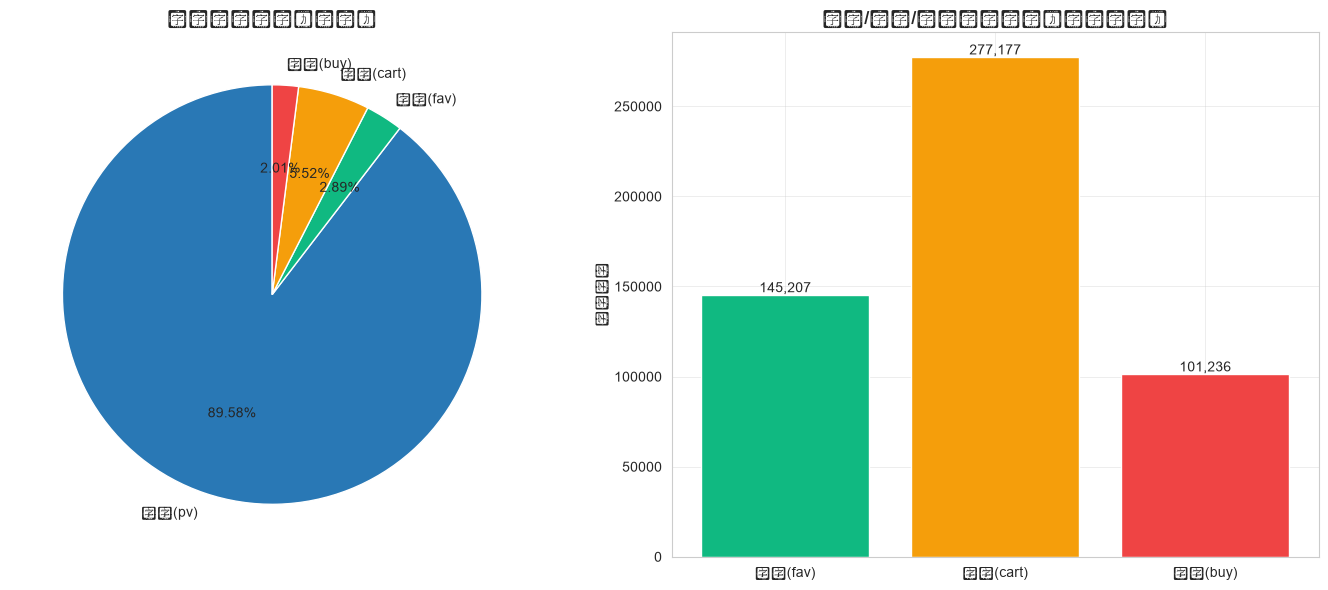

In [19]:
behavior_count = df['behavior_type'].value_counts().sort_index()
behavior_pct = df['behavior_type'].value_counts(normalize=True).sort_index() * 100
behavior_stats = pd.DataFrame({
    '行为次数':behavior_count,
    '占比':behavior_pct
})
behavior_stats = behavior_stats.reindex(['pv', 'fav', 'cart', 'buy'])
behavior_stats.index = ['点击(pv)', '收藏(fav)', '加购(cart)', '购买(buy)']
print('四种行为统计:')
print(behavior_stats)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#2978B5', '#10B981', '#F59E0B', '#EF4444']
wedges, texts, autotexts = ax1.pie(
    behavior_stats['行为次数'],
    labels=behavior_stats.index,
    autopct='%1.2f%%',
    colors=colors,
    startangle=90,
    textprops={'fontsize': 10}
)
ax1.set_title('行为类型占比（全部）', fontsize=13, fontweight='bold')
non_pv = behavior_stats.iloc[1:]  # 排除点击
bars = ax2.bar(non_pv.index, non_pv['行为次数'],
               color=colors[1:], edgecolor='white')
ax2.set_title('收藏/加购/购买数量对比（排除点击）',
              fontsize=13, fontweight='bold')
ax2.set_ylabel('行为次数')

for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, height,
             f'{height:,.0f}',
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('../data/03_behavior_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [21]:
pv_user_count = df[df['behavior_type'] == 'pv']['user_id'].nunique()
fav_user_count = df[df['behavior_type'] == 'fav']['user_id'].nunique()
cart_user_count = df[df['behavior_type'] == 'cart']['user_id'].nunique()
buy_user_count = df[df['behavior_type'] == 'buy']['user_id'].nunique()

pv_count = behavior_stats.loc['点击(pv)', '行为次数']
fav_count = behavior_stats.loc['收藏(fav)', '行为次数']
cart_count = behavior_stats.loc['加购(cart)', '行为次数']
buy_count = behavior_stats.loc['购买(buy)', '行为次数']

pv_to_fav = fav_count / pv_count * 100
pv_to_cart = cart_count / pv_count * 100
pv_to_buy = buy_count / pv_count * 100
cart_to_buy = buy_count / cart_count * 100
fav_to_buy = buy_count / fav_count * 100
user_pv_to_buy = buy_user_count / pv_user_count * 100
user_cart_to_buy = buy_user_count / cart_user_count * 100
print(f"点击 → 收藏:  {pv_to_fav:.2f}%")
print(f"点击 → 加购:  {pv_to_cart:.2f}%")
print(f"点击 → 购买:  {pv_to_buy:.2f}%")
print(f"加购 → 购买:  {cart_to_buy:.2f}%")
print(f"收藏 → 购买:  {fav_to_buy:.2f}%")
print(f"有点击行为的用户数: {pv_user_count:,} 人")
print(f"有加购行为的用户数: {cart_user_count:,} 人")
print(f"有购买行为的用户数: {buy_user_count:,} 人")
print(f"浏览用户 → 购买用户: {user_pv_to_buy:.2f}%")
print(f"加购用户 → 购买用户: {user_cart_to_buy:.2f}%")

点击 → 收藏:  3.23%
点击 → 加购:  6.16%
点击 → 购买:  2.25%
加购 → 购买:  36.52%
收藏 → 购买:  69.72%
有点击行为的用户数: 49,800 人
有加购行为的用户数: 37,273 人
有购买行为的用户数: 34,021 人
浏览用户 → 购买用户: 68.32%
加购用户 → 购买用户: 91.28%
